In [3]:
%pip install pixeltable-pgserver
%pip install psycopg

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 24.7/24.7 MB 57.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 215.5/215.5 kB 5.5 MB/s eta 0:00:00


In [4]:
import pixeltable_pgserver as pgserver

# 2. Запускаем сервер во временной директории Linux
server = pgserver.get_server('/tmp/my_db_data')
print("🔥 Сервер успішно запущений!")

# 3. Получаем строку подключения через рабочий метод get_uri()
db_url = server.get_uri()
print("Посилання для %sql:", db_url)

/usr/local/lib/python3.13/dist-packages/platformdirs/api.py:459: RuntimeDirWarning: XDG_RUNTIME_DIR is not set, falling back to /tmp/runtime-0
  return Path(self.user_runtime_dir)


🔥 Сервер успішно запущений!
Посилання для %sql: postgresql://postgres:@/postgres?host=/tmp/my_db_data


In [5]:
%load_ext sql
%sql postgresql://postgres:@/postgres?host=/tmp/my_db_data
%config SqlMagic.style = '_DEPRECATED_DEFAULT'

In [6]:
%%sql
SELECT version();

 * postgresql://postgres:***@/postgres?host=%2Ftmp%2Fmy_db_data
1 rows affected.


version
"PostgreSQL 18.4 on x86_64-pc-linux-gnu, compiled by gcc (GCC) 14.2.1 20250110 (Red Hat 14.2.1-11), 64-bit"



# Завдання 1. ER-діаграма 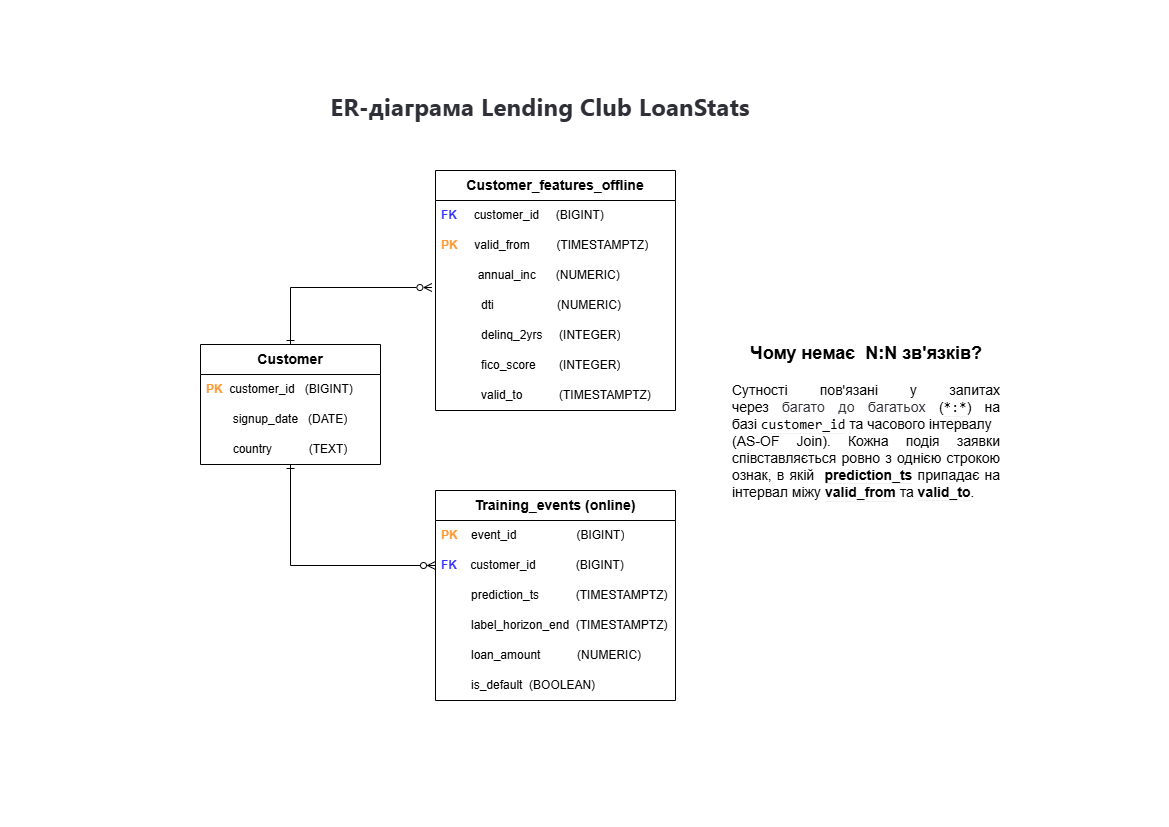

# Завдання 2. DDL у PostgreSQL

In [20]:
%%sql
SET TIME ZONE 'UTC';

DROP TABLE IF EXISTS
    hw2_training_events,
    hw2_customer_features_offline,
    hw2_customers
CASCADE;

-- Довідник позичальників
CREATE TABLE hw2_customers (
    customer_id BIGINT PRIMARY KEY,
    signup_date DATE NOT NULL,
    country     TEXT NOT NULL
);

-- Історичне сховище ознак (SCD Type 2)
CREATE TABLE hw2_customer_features_offline (
    customer_id       BIGINT NOT NULL REFERENCES hw2_customers(customer_id),
    annual_inc        NUMERIC(12, 2) NOT NULL CHECK (annual_inc >= 0),
    dti               NUMERIC(5, 2) NOT NULL CHECK (dti >= 0),
    delinq_2yrs       INTEGER NOT NULL CHECK (delinq_2yrs >= 0),
    fico_score        INTEGER NOT NULL CHECK (fico_score BETWEEN 300 AND 850),
    valid_from        TIMESTAMPTZ NOT NULL,
    valid_to          TIMESTAMPTZ,

    PRIMARY KEY (customer_id, valid_from),

    -- Критерій неможливості майбутнього valid_to <= valid_from
    CONSTRAINT chk_valid_dates CHECK (valid_to IS NULL OR valid_to > valid_from)
);

-- Індекс для оптимізації AS-OF JOIN
CREATE INDEX hw2_idx_customer_features_asof
    ON hw2_customer_features_offline (customer_id, valid_from DESC);

-- Реєстр заявок (Training Events)
CREATE TABLE hw2_training_events (
    event_id          BIGINT GENERATED BY DEFAULT AS IDENTITY PRIMARY KEY,
    customer_id       BIGINT NOT NULL REFERENCES hw2_customers(customer_id),
    prediction_ts     TIMESTAMPTZ NOT NULL,
    label_horizon_end TIMESTAMPTZ NOT NULL,
    loan_amount       NUMERIC(12, 2) NOT NULL CHECK (loan_amount > 0),
    is_default        BOOLEAN NOT NULL,

    CONSTRAINT chk_horizon CHECK (label_horizon_end > prediction_ts)
);


 * postgresql://postgres:***@/postgres?host=%2Ftmp%2Fmy_db_data
Done.
Done.
Done.
Done.
Done.
Done.


[]

# Завдання 3. Нормалізація   
У наведеній схемі таблиці сustomer, еraining_events та customer_features_offline  перебувають у третій нормальній формі (3НФ).   

• У Customer первинний ключ customer_id однозначно визначає неключові атрибути (функціональна залежність: \(customer\_id \rightarrow signup\_date, country\)). Тут відсутні часткові або транзитивні залежності.   

• У Training_events усі атрибути залежать виключно від композитного первинного ключа event_id, customer_id.   

• Таблиця Customer_features_offline створює для кожної зміни новий рядок у таблиці. Це дозволяє точно знати, якими були дані в будь-який конкретний момент у минулому для збереження історії. Вона перебуває у 3НФ відносно складеного первинного ключа (customer_id, valid_from), оскільки фінансові метрики та FICO-score жорстко прив'язані до конкретного часового інтервалу фіксації.  

Денормалізація та Online-рівень
Для обслуговування моделей машинного навчання в реальному часі (Inference) створюється окрема денормалізована online-таблиця (Feature Store). У ній зберігається лише один, найсвіжіший зріз ознак для кожного користувача.
Така денормалізація критично виправдана специфічним шаблоном читання (read pattern):
1. Швидкий lookup за customer_id: Сервіс робить точковий запит за ID клієнта в один потік.
2. Низька затримка (Low Latency): Онлайн-системи вимагають відповіді за мілісекунди, що робить сканування історичних інтервалів неприпустимим.
3. Зменшення кількості JOIN: Виключається потреба у важких операціях об'єднання (зокрема, AS-OF JOIN для пошуку актуальної дати), що суттєво заощаджує ресурси CPU та прискорює відповідь.


# Завдання 4. Point-in-Time correctness

In [21]:
%%sql
-- Очищуємо таблиці для заповнення
TRUNCATE hw2_training_events, hw2_customer_features_offline, hw2_customers CASCADE;

-- Створюємо 3 унікальні сущності (Entity ID: 1, 2, 42)
INSERT INTO hw2_customers (customer_id, signup_date, country) VALUES
(1,  DATE '2023-05-10', 'NY'),
(2,  DATE '2023-08-15', 'TX'),
(42, DATE '2023-01-01', 'CA');


-- Заповнюємо історію ознак (Всього 11 строк для 3 сущностей з UTC-літералами +00)

-- ПОЗИЧАЛЬНИК 1: 4  (плавна зміна фін. профілю)
INSERT INTO hw2_customer_features_offline (customer_id, annual_inc, dti, delinq_2yrs, fico_score, valid_from, valid_to) VALUES
(1, 45000.00, 15.00, 0, 720, TIMESTAMPTZ '2024-01-01 00:00:00+00', TIMESTAMPTZ '2024-05-01 00:00:00+00'),
(1, 50000.00, 22.40, 0, 690, TIMESTAMPTZ '2024-05-01 00:00:00+00', TIMESTAMPTZ '2024-09-01 00:00:00+00'),
(1, 55000.00, 28.10, 1, 650, TIMESTAMPTZ '2024-09-01 00:00:00+00', TIMESTAMPTZ '2024-12-01 00:00:00+00'),
(1, 60000.00, 20.00, 0, 680, TIMESTAMPTZ '2024-12-01 00:00:00+00', NULL);

-- ПОЗИЧАЛЬНИК 2: 4 (нестабільний та протиречивий фін. профіль)
INSERT INTO hw2_customer_features_offline (customer_id, annual_inc, dti, delinq_2yrs, fico_score, valid_from, valid_to) VALUES
(2, 80000.00, 10.00, 0, 750, TIMESTAMPTZ '2024-02-01 00:00:00+00', TIMESTAMPTZ '2024-06-01 00:00:00+00'),
(2, 80000.00, 35.50, 2, 610, TIMESTAMPTZ '2024-06-01 00:00:00+00', TIMESTAMPTZ '2024-10-01 00:00:00+00'),
(2, 85000.00, 30.00, 1, 630, TIMESTAMPTZ '2024-10-01 00:00:00+00', TIMESTAMPTZ '2024-12-15 00:00:00+00'),
(2, 90000.00, 12.00, 0, 740, TIMESTAMPTZ '2024-12-15 00:00:00+00', NULL);

-- ПОЗИЧАЛЬНИК 42: 3 (плавне покращення фін. профілю))
INSERT INTO hw2_customer_features_offline (customer_id, annual_inc, dti, delinq_2yrs, fico_score, valid_from, valid_to) VALUES
(42, 50000.00, 25.50, 1, 640, TIMESTAMPTZ '2024-01-01 00:00:00+00', TIMESTAMPTZ '2024-06-01 00:00:00+00'),
(42, 75000.00, 18.20, 0, 710, TIMESTAMPTZ '2024-06-01 00:00:00+00', TIMESTAMPTZ '2024-11-01 00:00:00+00'),
(42, 80000.00, 15.00, 0, 730, TIMESTAMPTZ '2024-11-01 00:00:00+00', NULL);


-- 3. Створюємо кредитні заявки (loan_amount)
INSERT INTO hw2_training_events (customer_id, prediction_ts, label_horizon_end, loan_amount, is_default) VALUES
-- Заявки Позичальника 1
(1, TIMESTAMPTZ '2024-07-15 10:00:00+00', TIMESTAMPTZ '2025-07-15 10:00:00+00', 5000.00,  FALSE),
(1, TIMESTAMPTZ '2024-12-20 14:30:00+00', TIMESTAMPTZ '2025-12-20 14:30:00+00', 25000.00, TRUE),

-- Заявки Позичальника 2
(2, TIMESTAMPTZ '2024-04-10 09:00:00+00', TIMESTAMPTZ '2025-04-10 09:00:00+00', 12000.00, FALSE),
(2, TIMESTAMPTZ '2024-11-01 12:00:00+00', TIMESTAMPTZ '2025-11-01 12:00:00+00', 35000.00, TRUE),

-- Заявки Позичальника 42
(42, TIMESTAMPTZ '2024-03-10 10:00:00+00', TIMESTAMPTZ '2025-03-10 10:00:00+00', 3000.00,  FALSE),
(42, TIMESTAMPTZ '2024-10-20 14:00:00+00', TIMESTAMPTZ '2025-10-20 14:00:00+00', 15000.00, TRUE);



 * postgresql://postgres:***@/postgres?host=%2Ftmp%2Fmy_db_data
Done.
3 rows affected.
4 rows affected.
4 rows affected.
3 rows affected.
6 rows affected.


[]

# AS-OF JOIN для  для формування training data

In [22]:
%%sql
SELECT DISTINCT ON (e.event_id)
    e.event_id,
    e.customer_id,
    e.prediction_ts AS application_date,
    e.loan_amount,

    -- Захист від  NULL
    COALESCE(f.annual_inc, 45000.00) AS annual_inc,
    COALESCE(f.dti, 20.00) AS dti,
    COALESCE(f.fico_score, 600) AS fico_score,

    -- Розрахунок коефіцієнта ( loan_amount / annual_inc )
    ROUND(e.loan_amount / COALESCE(f.annual_inc, 45000.00), 2) AS loan_to_income_ratio,

    e.is_default AS target_label
FROM hw2_training_events AS e
LEFT JOIN hw2_customer_features_offline AS f
    ON f.customer_id = e.customer_id
   AND f.valid_from <= e.prediction_ts
ORDER BY
    e.event_id,
    f.valid_from DESC;


 * postgresql://postgres:***@/postgres?host=%2Ftmp%2Fmy_db_data
6 rows affected.


event_id,customer_id,application_date,loan_amount,annual_inc,dti,fico_score,loan_to_income_ratio,target_label
1,1,2024-07-15 10:00:00+00:00,5000.00,50000.00,22.40,690,0.10,False
2,1,2024-12-20 14:30:00+00:00,25000.00,60000.00,20.00,680,0.42,True
3,2,2024-04-10 09:00:00+00:00,12000.00,80000.00,10.00,750,0.15,False
4,2,2024-11-01 12:00:00+00:00,35000.00,85000.00,30.00,630,0.41,True
5,42,2024-03-10 10:00:00+00:00,3000.00,50000.00,25.50,640,0.06,False
6,42,2024-10-20 14:00:00+00:00,15000.00,75000.00,18.20,710,0.20,True


# Запит 1 — AS-OF SELECT для однієї сутності (Момент часу 2024-07-15)
 Витягуємо профіль позичальника ID 1 на дату 2024-07-15. Очікуваний скор FICO: 690.

In [23]:
%%sql
SELECT customer_id, annual_inc, dti, fico_score, valid_from, valid_to
FROM hw2_customer_features_offline
WHERE customer_id = 1
  AND valid_from <= TIMESTAMPTZ '2024-07-15 10:00:00+00'
  AND (valid_to > TIMESTAMPTZ '2024-07-15 10:00:00+00' OR valid_to IS NULL);


 * postgresql://postgres:***@/postgres?host=%2Ftmp%2Fmy_db_data
1 rows affected.


customer_id,annual_inc,dti,fico_score,valid_from,valid_to
1,50000.00,22.40,690,2024-05-01 00:00:00+00:00,2024-09-01 00:00:00+00:00


# Запит 2 — AS-OF SELECT для другого моменту часу.  
Перевіряємо того ж самого позичальника ID 1, але вже на більш пізню дату 2024-12-20 (після додаткових змін профілю). Очікуємий скор FICO повинен змінитися на 680.

In [24]:
%%sql
SELECT customer_id, annual_inc, dti, fico_score, valid_from, valid_to
FROM hw2_customer_features_offline
WHERE customer_id = 1
  AND valid_from <= TIMESTAMPTZ '2024-12-20 14:30:00+00'
  AND (valid_to > TIMESTAMPTZ '2024-12-20 14:30:00+00' OR valid_to IS NULL);


 * postgresql://postgres:***@/postgres?host=%2Ftmp%2Fmy_db_data
1 rows affected.


customer_id,annual_inc,dti,fico_score,valid_from,valid_to
1,60000.00,20.00,680,2024-12-01 00:00:00+00:00,None


# Запит 3 — Пакетний AS-OF JOIN для формування тренувального датасету.  

Цей запит поєднує всі training_events с offline-фічами суворо на відповідний момент заявки prediction_ts, гарантуючи захист від Data Leakage.

In [25]:
%%sql
SELECT
    e.event_id,
    e.customer_id,
    e.prediction_ts AS application_date,
    f.annual_inc,
    f.dti,
    f.fico_score,
    e.is_default AS target_label
FROM hw2_training_events AS e
LEFT JOIN hw2_customer_features_offline AS f
    ON f.customer_id = e.customer_id
   AND f.valid_from <= e.prediction_ts
   AND (
        f.valid_to > e.prediction_ts
        OR f.valid_to IS NULL
       )
ORDER BY e.customer_id, e.prediction_ts;


 * postgresql://postgres:***@/postgres?host=%2Ftmp%2Fmy_db_data
6 rows affected.


event_id,customer_id,application_date,annual_inc,dti,fico_score,target_label
1,1,2024-07-15 10:00:00+00:00,50000.00,22.40,690,False
2,1,2024-12-20 14:30:00+00:00,60000.00,20.00,680,True
3,2,2024-04-10 09:00:00+00:00,80000.00,10.00,750,False
4,2,2024-11-01 12:00:00+00:00,85000.00,30.00,630,True
5,42,2024-03-10 10:00:00+00:00,50000.00,25.50,640,False
6,42,2024-10-20 14:00:00+00:00,75000.00,18.20,710,True


# Контрольна перевірка Data Quality (Пошук перекривних інтервалів)
Запит для перевірки критичної помилки: він повинен повернути ровно 0 строк. Це буде доказом, що тимчасові інтервали часу не накладаються один на одного.

In [26]:
%%sql
SELECT
    a.customer_id,
    a.valid_from AS a_from,
    a.valid_to   AS a_to,
    b.valid_from AS b_from,
    b.valid_to   AS b_to
FROM hw2_customer_features_offline AS a
JOIN hw2_customer_features_offline AS b
  ON a.customer_id = b.customer_id
 AND a.valid_from < COALESCE(b.valid_to, 'infinity'::timestamptz)
 AND b.valid_from < COALESCE(a.valid_to, 'infinity'::timestamptz)
 AND a.valid_from < b.valid_from;


 * postgresql://postgres:***@/postgres?host=%2Ftmp%2Fmy_db_data
0 rows affected.


customer_id,a_from,a_to,b_from,b_to



# Обґрунтування логіки Point-in-Time Correctness та аналіз часових фільтрів

У процесі підготовки аналітичних вітрин для моделей машинного навчання (особливо в домені Credit Risk) критично важливо забезпечити Point-in-Time Correctness (коректність даних на момент часу) та повністю виключити Data Leakage (витік даних із майбутнього). Ниче наведено розбір логіки роботи часових фільтрів.

1. Чому використовується умова valid_from <= prediction_ts?

Ця умова гарантує, що версія ознак (фінансові показники заємщика, такі як рейтинг FICO чи дохід) уже була офіційно зафіксована та існувала до або в точний момент подачі кредитної заявки (prediction_ts).
Модель скорингу в реальному часі (у продакшені) може спиратися лише на ті факти, які відомі на момент прийняття рішення. Будь-які записи, де valid_from > prediction_ts, є подіями з майбутнього, про які система в поточній точці часу ще не знає.

2. Чому для верхньої межі використовується valid_to > prediction_ts OR valid_to IS NULL?

Ця конструкція визначає, чи була конкретна версія ознак усе ще актуальною (чинною) на момент здійснення події prediction_ts.   
Умова valid_to > prediction_ts відсікає застарілі версії ознак, які вже були замінені новішими оновленнями (наприклад, старий дохід, який змінився до моменту подачі поточної заявки).
А умова valid_to IS NULL покриває поточний (найсвіжіший) стан заємщика. В архітектурі SCD Type 2 значення NULL у полі valid_to означає математичну нескінченність (версія діє по сей день і не була перезаписана іншим станом).

3. Чому інтервали трактуються як напіввідкриті (valid_from, valid_to)?

Напіввідкритий інтервал забезпечує безперервність часу та унікальність стану заємщика без накладання версій одна на одну:  
- Квадратна дужка [ означає включення: момент valid_from є початком дії нової версії фіч.  
- Кругла дужка ) означає виключення: момент valid_to є точкою, коли ця версія перестає діяти, поступаючись місцем наступній.   
Завдяки такій семантиці, якщо фінансовий профіль оновився рівно о 12:00:00, стара версія закривається цим часом (не включаючи його), а нова — відкривається (включаючи його). Це гарантує, що для будь-якої точки часу prediction_ts завжди знайдеться строго одна валідна версія ознак, що запобігає дублюванню рядків при JOIN.

4. Які дані потрапили б із майбутнього, якби часовий фільтр був відсутній?

Якби ми використати наївний JOIN лише за ідентифікатором заємщика (ON f.customer_id = e.customer_id), відбувся б повний витік даних із майбутнього (Data Leakage):   

 - Витік майбутніх фіч: Для першої кредитної заявки заємщика ID 1 (від 2024-07-15) модель отримала б дані його майбутнього профілю від грудня 2024 року (де його дохід зріс до $60,000). Модель оцінювала б ризик на основі грошей, яких у заємщика на момент заявки ще не було.   

 - Витік цільової змінної (Post-Outcome): У модель могли б просочитися ознаки, розраховані вже після видачі кредиту (наприклад, інформація про прострочення, стягнення чи факт першого платежу).    

 - Наслідки: Модель просто «зазубрить» майбутні фінансові покращення/погіршення клієнтів. На історичних даних точність буде 100%, але в продакшені її якість буде нульовою, оскільки вона не зможе знайти маркерів майбутнього у нових аплікантів. Крім того, такий JOIN розмножив би кількість рядків у датасеті (помножив кожну заявку на всі історичні версії фіч клієнта).

# Рефлексія та інженерний аналіз проєктування (Reflection)


1. Найскладніший етап проєктування

Найбільшим викликом під час розробки архітектури Feature Store для кредитного ризику стала реалізація Point-in-Time Correctness за допомогою часових інтервалів [valid_from, valid_to). На відміну от стандартної нормалізації або визначення кардинальностей для OLTP-систем, проектування часової шкали вимагає суворого врахування динаміки фінансових метрик заемщика. Було складно ментально забезпечити повну відсутність накладання версій при фільтрації, оскільки найменша помилка в операторах порівняння призводить до дублювання записів кредитного скорингу або критичного витоку даних із майбутнього (Data Leakage).

2. Проєктні компроміси (Компроміси архітектури)

Для оптимізації процесів читання та запису було обрано гібридний підхід:
• Нормалізація: Базові сутності заемщиків (hw2_customers) винесені в окрему таблицю для уникнення дублювання статичних атрибутів (регіон, дата реєстрації). Це оптимізує оновлення довідників СУБД.
• Навмисна денормалізація: Зрізи динамічних ознак у таблиці hw2_customer_features_offline спроєктовані як «широкі рядки» з готовими агрегатами (annual_inc, fico_score, dti).
• Відповідність сценаріям: Цей компроміс ідеальний для аналітичного читання (OLAP) та ML-пайплайнів: під час збору датасету нам не потрібно «на льоту» розраховувати показники з логів банківських транзакцій. Дані оновлюються фоновим батч-процесом раз на добу, забезпечуючи миттєве пакетне читання.

3. Масштабування Online-рівня для високонавантаженого інференсу

Якби кредитний конвеєр обробляв мільйони запитів, а lookup мав тривати < 10 мс, я б виніс online-рівень із реляційної бази до розподіленого In-Memory NoSQL-сховища (наприклад, Redis або DynamoDB). Ознаки зберігалися б як один повністю денормалізований рядок (або JSON) за ключем customer_id. Попередня матеріалізація фіч відбувалась би за допомогою потокової обробки (Flink/Spark Streaming) на основі подій із сервіса повідомлень (Kafka). Горизонтальне масштабування досягалося б шардуванням даних за customer_id, а контроль свіжості (stateness) моніторився б через порівняння мітки feature_ts із поточним часом.

4. Ризики еволюції схеми протягом 6 місяців

Життєвий цикл ML-систем у кредитному скорингу неминуче стикається з деградацією та зміною даних. Найбільші ризики включають:
• Зміна семантики фіч. Наприклад, бізнес вирішить перейти з моделі рейтингу FICO Score 1 на FICO Score 2, що повністю змінить розподіл даних у колонці.
• Підтримка старих моделей. Якщо в продакшені паралельно працюють дві версії моделей (V1 та V2), видалення або зміна типів даних у витрині зламає інференс або перенавчання старої моделі. Для мінімізації цих ризиків необхідно впроваджувати версіонування не лише моделей, а й самих фіч (Feature Versioning), додаючи нові колонки замість модифікації чи видалення старих.

===================================================================================================

# Експериментуємо: додаємо нових позичальників

In [27]:
%%sql

INSERT INTO hw2_customers (customer_id, signup_date, country) VALUES
(777, DATE '2026-01-01', 'FL'),
(999, DATE '2026-01-01', 'NY');

INSERT INTO hw2_customer_features_offline (customer_id, annual_inc, dti, delinq_2yrs, fico_score, valid_from, valid_to) VALUES
(999, 30000.00, 65.20, 4, 450, TIMESTAMPTZ '2026-02-01 00:00:00+00', NULL);

INSERT INTO hw2_training_events (customer_id, prediction_ts, label_horizon_end, loan_amount, is_default) VALUES
(777, TIMESTAMPTZ '2026-03-01 10:00:00+00', TIMESTAMPTZ '2027-03-01 10:00:00+00', 1500.00, FALSE),
(999, TIMESTAMPTZ '2026-03-01 11:00:00+00', TIMESTAMPTZ '2027-03-01 11:00:00+00', 50000.00, TRUE);

 * postgresql://postgres:***@/postgres?host=%2Ftmp%2Fmy_db_data
2 rows affected.
1 rows affected.
2 rows affected.


[]

In [95]:
%%sql
SELECT DISTINCT ON (e.event_id)
    e.event_id,
    e.customer_id,
    e.loan_amount,

    -- Збираємо фичи из Feature Store
    COALESCE(f.annual_inc, 45000.00) AS annual_inc,
    COALESCE(f.dti, 20.00) AS dti,
    COALESCE(f.fico_score, 600) AS fico_score,
    ROUND(e.loan_amount / COALESCE(f.annual_inc, 45000.00), 2) AS loan_to_income_ratio,

    -- Імітація логіки моделі (Бізнес-правила прийняття рішення)
    CASE
        WHEN COALESCE(f.fico_score, 600) < 550 THEN 'ВІДМОВА: Дуже низький кредитний рейтинг (FICO)'
        WHEN COALESCE(f.dti, 20.00) > 50.00 THEN 'ВІДМОВА: Критичне боргове навантаження (DTI)'
        WHEN (e.loan_amount / COALESCE(f.annual_inc, 45000.00)) > 1.0 THEN 'ВІДМОВА: Сумма кредиту перевищує річний дохід'
        ELSE 'СХВАЛЕНО: Клієнт проходить по критеріях ризику'
    END AS model_decision

FROM hw2_training_events AS e
LEFT JOIN hw2_customer_features_offline AS f
    ON f.customer_id = e.customer_id
   AND f.valid_from <= e.prediction_ts
WHERE e.customer_id IN (777, 999)
ORDER BY e.event_id, f.valid_from DESC;


 * postgresql://postgres:***@/postgres?host=%2Ftmp%2Fmy_db_data
2 rows affected.


event_id,customer_id,loan_amount,annual_inc,dti,fico_score,loan_to_income_ratio,model_decision
7,777,1500.00,45000.00,20.00,600,0.03,СХВАЛЕНО: Клієнт проходить по критеріях ризику
8,999,50000.00,30000.00,65.20,450,1.67,ВІДМОВА: Дуже низький кредитний рейтинг (FICO)


# Оновлений перелік в базі даних після додавання нових клієнтів

In [37]:
%%sql
SELECT DISTINCT ON (e.event_id)
    e.event_id,
    e.customer_id,
    c.country,
    e.prediction_ts AS application_date,
    e.loan_amount,

    COALESCE(f.annual_inc, 45000.00) AS annual_inc,
    COALESCE(f.dti, 20.00) AS dti,
    COALESCE(f.fico_score, 600) AS fico_score,

    -- Динамічний показник кредитного навантаження
    ROUND(e.loan_amount / COALESCE(f.annual_inc, 45000.00), 2) AS loan_to_income_ratio,

    -- Іторичний таргет (факт дефолту, зафіксований по завершенню горизонту спостереження)
    e.is_default AS target_label

FROM hw2_training_events AS e
JOIN hw2_customers AS c
    ON e.customer_id = c.customer_id
LEFT JOIN hw2_customer_features_offline AS f
    ON f.customer_id = e.customer_id
   AND f.valid_from <= e.prediction_ts
ORDER BY
    e.event_id,
    f.valid_from DESC;


 * postgresql://postgres:***@/postgres?host=%2Ftmp%2Fmy_db_data
8 rows affected.


event_id,customer_id,country,application_date,loan_amount,annual_inc,dti,fico_score,loan_to_income_ratio,target_label
1,1,NY,2024-07-15 10:00:00+00:00,5000.00,50000.00,22.40,690,0.10,False
2,1,NY,2024-12-20 14:30:00+00:00,25000.00,60000.00,20.00,680,0.42,True
3,2,TX,2024-04-10 09:00:00+00:00,12000.00,80000.00,10.00,750,0.15,False
4,2,TX,2024-11-01 12:00:00+00:00,35000.00,85000.00,30.00,630,0.41,True
5,42,CA,2024-03-10 10:00:00+00:00,3000.00,50000.00,25.50,640,0.06,False
6,42,CA,2024-10-20 14:00:00+00:00,15000.00,75000.00,18.20,710,0.20,True
7,777,FL,2026-03-01 10:00:00+00:00,1500.00,45000.00,20.00,600,0.03,False
8,999,NY,2026-03-01 11:00:00+00:00,50000.00,30000.00,65.20,450,1.67,True
